In [17]:
import numpy as np, pandas as pd, time
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import truncnorm
import dynesty
from dynesty import utils as dyfunc
from scipy.optimize import curve_fit

In [11]:
def modelo_banda(t, A, beta, gamma, t0, tau_rise, tau_fall):
    """Ecuación 1 del paper, para una banda. t y t0 en días."""
    dt = t - t0
    subida = A / (1 + np.exp(-dt / tau_rise))
    plateau = 1 - beta * dt
    caida = (1 - beta * gamma) * np.exp((gamma - dt) / tau_fall)
    return subida * np.where(dt < gamma, plateau, caida)

In [12]:
def ajusta_banda(c, t_ref):
    t = c["mjd"].to_numpy() - t_ref            # tiempos relativos al máximo en r
    f = c["flujo"].to_numpy()
    e = c["flujo_err"].to_numpy()
    fm = f.max()
    p0  = [1.25 * fm, 0.0083, 27, -18, 4.7, 34]       # arranque: centros de los priors
    inf = [0.5 * fm, 1e-4, 1.0, -100, 0.01, 1.0]      
    sup = [3.16 * fm, 0.03, 3162, 30, 1e4, 1e4]
    popt, _ = curve_fit(modelo_banda, t, f, p0=p0, sigma=e,
                        bounds=(inf, sup), maxfev=20000)
    chi2 = np.mean(((f - modelo_banda(t, *popt)) / e) ** 2)
    # cuántos parámetros terminaron pegados a un límite
    n_lim = int(np.sum(np.isclose(popt, inf, rtol=1e-3, atol=1e-6) |
                       np.isclose(popt, sup, rtol=1e-3, atol=1e-6)))
    return popt, chi2, t, n_lim

In [2]:
PROC = Path("../data/processed")

def tn(u, mu, sd, lo, hi):
    """Gaussiana truncada: transforma u en [0,1] a un valor de la distribución."""
    return truncnorm.ppf(u, (lo - mu) / sd, (hi - mu) / sd, loc=mu, scale=sd)

def prior_transform(u, fmax):
    A        = fmax * 10 ** tn(u[0], 0.096, 0.058, -0.3, 0.5)
    beta     = tn(u[1], 8.3e-3, 3.9e-3, 0.0, 0.03)
    gamma    = 10 ** tn(u[2], 1.43, 0.31, 0.0, 3.5)
    t0       = tn(u[3], -17.9, 9.9, -100.0, 30.0)        
    tau_rise = 10 ** tn(u[4], 0.67, 0.43, -2.0, 4.0)
    tau_fall = 10 ** tn(u[5], 1.53, 0.30, 0.0, 4.0)
    sigma    = fmax * 10 ** tn(u[6], -1.66, 0.34, -3.0, -0.8)   # sigma_extra
    return np.array([A, beta, gamma, t0, tau_rise, tau_fall, sigma])

In [7]:
def loglike(theta, t, f, e):
    A, beta, gamma, t0, tau_rise, tau_fall, sig = theta
    beta = max(beta, 1e-9)                                   # evita dividir entre cero
    with np.errstate(all="ignore"):
        if np.exp(-gamma / tau_rise) * (1 / beta - tau_rise - gamma) > tau_rise:   # ec. B2
            return -1e30
        if gamma > (1 - beta * tau_fall) / beta:                                   # ec. B3
            return -1e30
        var = e ** 2 + sig ** 2
        modelo = modelo_banda(t, A, beta, gamma, t0, tau_rise, tau_fall)
        ll = -0.5 * np.sum((f - modelo) ** 2 / var + np.log(2 * np.pi * var))
    return ll if np.isfinite(ll) else -1e30

Aca podemos tener en cuenta el error de las curvas sig.

In [8]:
def ajusta_dynesty(c, seed=0):
    t = c["mjd"].to_numpy(); f = c["flujo"].to_numpy(); e = c["flujo_err"].to_numpy()
    tt = t - t[f.argmax()]; fmax = f.max()
    sampler = dynesty.NestedSampler(
        lambda th: loglike(th, tt, f, e),
        lambda u: prior_transform(u, fmax),
        ndim=7, nlive=50, bound="single", sample="rwalk",
        rstate=np.random.default_rng(seed))
    sampler.run_nested(dlogz=0.5, maxiter=5000, print_progress=False)
    res = sampler.results
    pesos = np.exp(res.logwt - res.logz[-1])
    return dyfunc.resample_equal(res.samples, pesos), tt, res

Aqui aplicamos el muestreo Bayesiano con los parametros que indica el articulo.

**Prueba**

In [13]:
nombre = "ZTF20acbeanu"
cr = pd.read_parquet(PROC / f"{nombre}.parquet").query("banda == 'r'")

t_ini = time.time()
muestras, tt, res = ajusta_dynesty(cr)
print("tiempo:", round(time.time() - t_ini, 1), "s | muestras:", len(muestras),
      "| evaluaciones:", int(np.sum(res.ncall)))

tiempo: 30.3 s | muestras: 828 | evaluaciones: 18144


                  p16   mediana       p84  curve_fit
A            1766.597  1872.135  2011.775   2045.900
beta            0.007     0.011     0.015      0.019
gamma          10.057    11.464    13.258     12.324
t0             -5.198    -4.817    -4.436     -4.343
tau_rise        2.061     2.391     2.765      2.589
tau_fall       20.450    22.329    24.899     22.344
sigma_extra    10.921    20.177    33.901        NaN


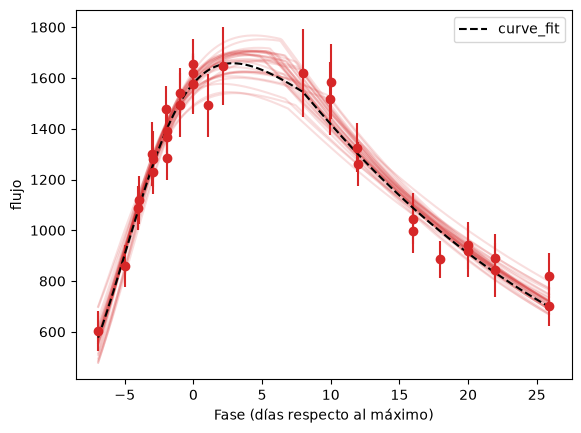

In [18]:
nom = ["A", "beta", "gamma", "t0", "tau_rise", "tau_fall", "sigma_extra"]
q = np.percentile(muestras, [16, 50, 84], axis=0)
t_ref = cr["mjd"].to_numpy()[cr["flujo"].to_numpy().argmax()]
popt, chi2, _, _ = ajusta_banda(cr, t_ref)
tabla = pd.DataFrame({"p16": q[0], "mediana": q[1], "p84": q[2]}, index=nom)
tabla["curve_fit"] = list(popt) + [np.nan]
print(tabla.round(3))

tg = np.linspace(tt.min(), tt.max(), 300)
elegidas = np.random.default_rng(0).choice(len(muestras), 30, replace=False)
for th in muestras[elegidas]:
    plt.plot(tg, modelo_banda(tg, *th[:6]), color="tab:red", alpha=0.15)
plt.errorbar(tt, cr["flujo"], yerr=cr["flujo_err"], fmt="o", color="tab:red")
plt.plot(tg, modelo_banda(tg, *popt), "k--", label="curve_fit")
plt.xlabel("Fase (días respecto al máximo)"); plt.ylabel("flujo"); plt.legend(); plt.show()